# 01 Data processing

Builds a clean, leakage-free image dataset from Fitzpatrick17k for knowledge graph-guided skin disease recognition.

**Inputs**: `fitzpatrick17k.csv` and the image folder. Nothing else is required.
**Outputs** (`data_v2/`):

| File | Content |
|---|---|
| `meta.csv` | one row per clean image: path, labels, skin type, splits, frequency bin |
| `taxonomy.csv` | disease id, name, nine-category and three-category labels |
| `class_stats.csv` | per-disease counts per split, frequency bin, seen/unseen |
| `duplicates.csv` | duplicate clusters and how each was resolved |
| `cache/*.jpg` | resized RGB copies for fast feature extraction |
| `summary.json` | all counts from this notebook |

Steps: 1 index, 2 integrity, 3 duplicates, 4 taxonomy, 5 splits, 6 statistics, 7 image cache, 8 save.

`pip install pandas numpy pillow imagehash tqdm matplotlib`

In [32]:
# ============ Config ============
from pathlib import Path

ROOT        = Path('.')
IMG_DIR     = ROOT / 'images'              # downloaded Fitzpatrick17k images
FITZ_CSV    = ROOT / 'fitzpatrick17k.csv'
OUT         = ROOT / 'data_v2'
FIG         = ROOT / 'figures_v2'

SEED        = 42
N_WORKERS   = 8
MIN_SIDE    = 64        # drop images whose shorter side is below this
PHASH_THR   = 4         # near-duplicate Hamming distance (0-64); calibrate in step 3
PHASH_MAX   = 10        # largest distance kept for the threshold sweep
VAL_FRAC    = 0.10
TEST_FRAC   = 0.20
UNSEEN_FRAC = 0.20      # fraction of diseases held out as unseen (zero-shot)
CACHE_SIDE  = 512       # shorter side of cached images; 0 disables the cache
FORCE       = False     # True: recompute cached inspection and image cache

OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

In [33]:
import io, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
import imagehash
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

rng = np.random.default_rng(SEED)
LOG = {}

def norm_id(s):
    return (s.astype(str).str.strip().str.lower()
             .str.replace(r'\.(jpe?g|png|bmp|webp|tiff?)$', '', regex=True))

def pmap(fn, items, desc):
    with ThreadPoolExecutor(N_WORKERS) as ex:
        return list(tqdm(ex.map(fn, items), total=len(items), desc=desc))

## 1. Index

In [34]:
fitz = pd.read_csv(FITZ_CSV)
fitz['md5hash'] = norm_id(fitz['md5hash'])
fitz['label'] = fitz['label'].astype(str).str.strip().str.lower()
LOG['csv_rows'] = len(fitz)
LOG['csv_dup_rows'] = int(fitz['md5hash'].duplicated().sum())
fitz = fitz.drop_duplicates('md5hash').reset_index(drop=True)

EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}
files = {}
for p in IMG_DIR.rglob('*'):
    if p.suffix.lower() in EXTS:
        files.setdefault(p.stem.lower(), p)
fitz['path'] = fitz['md5hash'].map(lambda h: str(files[h]) if h in files else None)

LOG['image_files'] = len(files)
LOG['missing'] = int(fitz['path'].isna().sum())
LOG['files_not_in_csv'] = len(set(files) - set(fitz['md5hash']))
print(f"CSV rows {LOG['csv_rows']} | diseases {fitz['label'].nunique()} | image files {len(files)}")
print(f"matched {fitz['path'].notna().sum()} | missing {LOG['missing']} | extra files {LOG['files_not_in_csv']}")

CSV rows 16577 | diseases 114 | image files 16577
matched 16577 | missing 0 | extra files 0


## 2. Integrity

In [35]:
def inspect(path):
    r = dict(path=path, ok=False, w=np.nan, h=np.nan, mode=None, md5_bytes=None, phash=None, err=None)
    try:
        b = Path(path).read_bytes()
        r['md5_bytes'] = hashlib.md5(b).hexdigest()
        with Image.open(io.BytesIO(b)) as im:
            im.verify()
        with Image.open(io.BytesIO(b)) as im:
            im = im.convert('RGB')
            r['w'], r['h'] = im.size
            r['phash'] = str(imagehash.phash(im))
        with Image.open(io.BytesIO(b)) as im:
            r['mode'] = im.mode
        r['ok'] = True
    except Exception as e:
        r['err'] = repr(e)[:200]
    return r

cache_file = OUT / 'inspect.csv'
if cache_file.exists() and not FORCE:
    info = pd.read_csv(cache_file, dtype={'phash': str, 'md5_bytes': str})
else:
    info = pd.DataFrame(pmap(inspect, fitz['path'].dropna().tolist(), 'inspect'))
    info.to_csv(cache_file, index=False)

df = fitz.merge(info, on='path', how='left')
df['ok'] = df['ok'].fillna(False).astype(bool)
df['drop_reason'] = None
df.loc[df['path'].isna(), 'drop_reason'] = 'missing'
df.loc[df['path'].notna() & ~df['ok'], 'drop_reason'] = 'corrupt'
df.loc[df['ok'] & (np.minimum(df['w'], df['h']) < MIN_SIDE), 'drop_reason'] = 'small'
df.loc[df['drop_reason'].isna() & df['qc'].astype(str).str.startswith('3'), 'drop_reason'] = 'qc_wrong_label'

print(df['drop_reason'].value_counts().to_string())
print('modes:', df.loc[df.ok, 'mode'].value_counts().to_dict())
print(df.loc[df.ok, ['w', 'h']].describe(percentiles=[.05, .5, .95]).round(0).T.to_string())

inspect: 100%|██████████| 16577/16577 [00:26<00:00, 626.49it/s]


drop_reason
qc_wrong_label    17
modes: {'RGB': 16574, 'L': 3}
     count   mean    std   min     5%    50%     95%     max
w  16577.0  526.0  313.0  87.0  289.0  458.0  1126.0  3872.0
h  16577.0  454.0  268.0  66.0  192.0  385.0   949.0  3288.0


## 3. Duplicates

In [36]:
cand = df[df['drop_reason'].isna()].copy().reset_index(drop=True)
n = len(cand)
H = np.array([int(h, 16) for h in cand['phash']], dtype=np.uint64)
POP = np.array([bin(i).count('1') for i in range(256)], dtype=np.uint8)

def hamming_pairs(H, thr, chunk=512):
    n, out = len(H), []
    for i in range(0, n, chunk):
        x = H[i:i + chunk, None] ^ H[None, :]
        d = POP[x.view(np.uint8)].reshape(x.shape[0], n, 8).sum(2, dtype=np.uint8)
        r, c = np.nonzero(d <= thr)
        k = (r + i) < c
        out.append(np.stack([r[k] + i, c[k], d[r[k], c[k]]], 1))
    return np.concatenate(out) if out else np.zeros((0, 3), dtype=int)

pairs = hamming_pairs(H, PHASH_MAX)
for _, g in cand.groupby('md5_bytes'):                      # byte-identical files
    if len(g) > 1:
        i = g.index.to_numpy()
        pairs = np.vstack([pairs, np.stack([i[:-1], i[1:], np.zeros(len(i) - 1, int)], 1)])

lab = cand['label'].to_numpy()
sweep = pd.DataFrame([dict(thr=t, pairs=int((pairs[:, 2] <= t).sum()),
                           cross_label=int(((pairs[:, 2] <= t) & (lab[pairs[:, 0]] != lab[pairs[:, 1]])).sum()))
                      for t in range(0, PHASH_MAX + 1)])
sweep.to_csv(OUT / 'phash_sweep.csv', index=False)
print(sweep.to_string(index=False))

 thr  pairs  cross_label
   0     55            3
   1     55            3
   2    153            9
   3    153            9
   4    223           19
   5    223           19
   6    301           32
   7    301           32
   8    439           81
   9    439           81
  10    837          300


Calibrate `PHASH_THR`: if pairs at the threshold are the same lesion, raise it; if pairs just below it are different lesions, lower it.

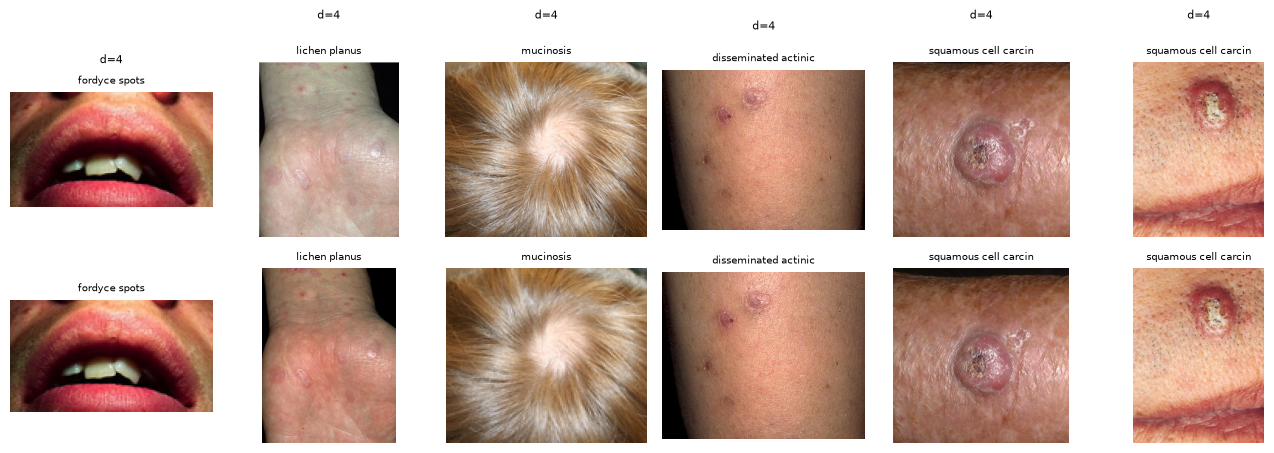

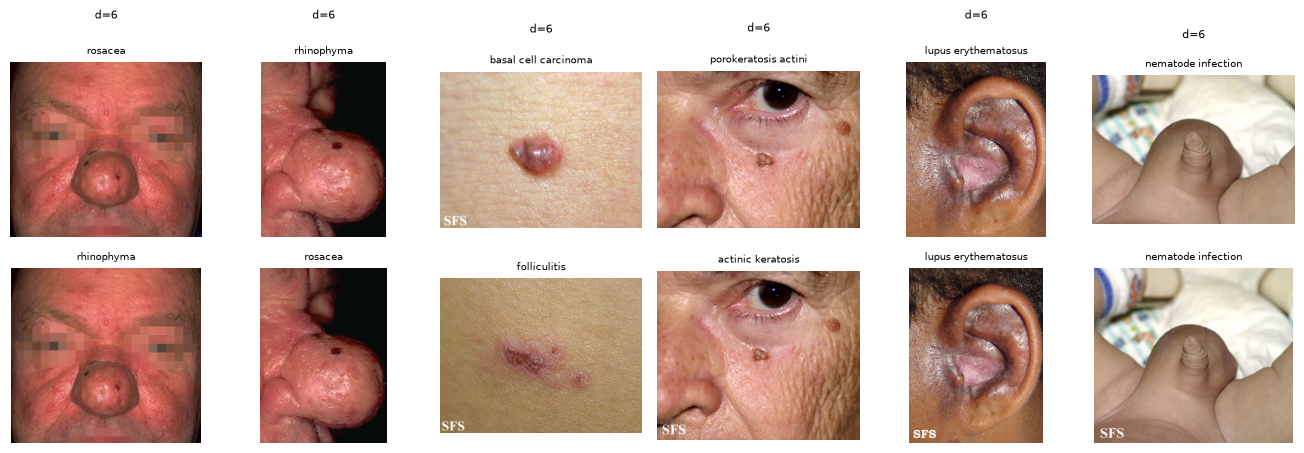

In [37]:
def show_pairs(dmin, dmax, k=6):
    sel = pairs[(pairs[:, 2] >= dmin) & (pairs[:, 2] <= dmax)]
    if not len(sel):
        print(f'no pairs at distance {dmin}-{dmax}'); return
    sel = sel[rng.choice(len(sel), min(k, len(sel)), replace=False)]
    fig, ax = plt.subplots(2, len(sel), figsize=(2.2 * len(sel), 4.6), squeeze=False)
    for j, (a, b, d) in enumerate(sel):
        for i, idx in enumerate((a, b)):
            ax[i, j].imshow(Image.open(cand.at[idx, 'path']).convert('RGB'))
            ax[i, j].set_title(cand.at[idx, 'label'][:20], fontsize=7)
            ax[i, j].axis('off')
        ax[0, j].text(.5, 1.25, f'd={d}', transform=ax[0, j].transAxes, ha='center', fontsize=8)
    plt.tight_layout(); plt.show()

show_pairs(max(PHASH_THR - 1, 0), PHASH_THR)
show_pairs(PHASH_THR + 1, PHASH_THR + 3)

In [38]:
parent = np.arange(n)
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]; a = parent[a]
    return a
for a, b, _ in pairs[pairs[:, 2] <= PHASH_THR]:
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra

cand['dup_cluster'] = [find(i) for i in range(n)]
g = cand.groupby('dup_cluster')
cand['dup_size'] = g['md5hash'].transform('size')
cand['dup_conflict'] = g['label'].transform('nunique') > 1
cand['area'] = cand['w'] * cand['h']

# one image per label-consistent cluster (the largest);
# clusters whose copies carry different labels are dropped as label noise
keep = (cand[~cand['dup_conflict']].sort_values('area', ascending=False)
        .groupby('dup_cluster').head(1).index)
cand['dup_action'] = np.where(cand['dup_conflict'], 'drop_conflict',
                     np.where(cand.index.isin(keep), 'keep', 'drop_redundant'))
cand.loc[cand['dup_size'] > 1,
         ['md5hash', 'label', 'dup_cluster', 'dup_size', 'dup_action']
        ].sort_values('dup_cluster').to_csv(OUT / 'duplicates.csv', index=False)

LOG['dup_clusters'] = int(cand.loc[cand.dup_size > 1, 'dup_cluster'].nunique())
LOG.update({k: int(v) for k, v in cand['dup_action'].value_counts().items() if k != 'keep'})
data = cand[cand['dup_action'] == 'keep'].reset_index(drop=True)
print(cand['dup_action'].value_counts().to_string())
print(f'clean images: {len(data)} | diseases: {data.label.nunique()}')

dup_action
keep              16321
drop_redundant      201
drop_conflict        38
clean images: 16321 | diseases: 114


## 4. Taxonomy

In [39]:
tax = (data.groupby('label')
       .agg(category=('nine_partition_label', lambda s: s.mode().iat[0]),
            super_category=('three_partition_label', lambda s: s.mode().iat[0]),
            n_images=('md5hash', 'size'))
       .reset_index().rename(columns={'label': 'disease'})
       .sort_values(['super_category', 'category', 'disease']).reset_index(drop=True))
tax['disease_id'] = np.arange(len(tax))
incons = data.groupby('label')['nine_partition_label'].nunique()
print(f'{len(tax)} diseases | {tax.category.nunique()} categories | {tax.super_category.nunique()} super-categories')
print('diseases with inconsistent category labels:', int((incons > 1).sum()))
print(tax.groupby(['super_category', 'category']).size().to_string())

114 diseases | 9 categories | 3 super-categories
diseases with inconsistent category labels: 0
super_category  category                    
benign          benign dermal                   12
                benign epidermal                 9
                benign melanocyte                3
malignant       malignant cutaneous lymphoma     1
                malignant dermal                 1
                malignant epidermal              5
                malignant melanoma               4
non-neoplastic  genodermatoses                  10
                inflammatory                    69


## 5. Splits

In [40]:
# 5a. unseen diseases: ~UNSEEN_FRAC per category, so every category keeps seen diseases
unseen = []
for cat, g in tax.groupby('category'):
    k = int(round(UNSEEN_FRAC * len(g)))
    k = min(max(k, 1 if len(g) >= 3 else 0), len(g) - 1)
    unseen += rng.choice(g['disease'].to_numpy(), k, replace=False).tolist()
tax['unseen'] = tax['disease'].isin(unseen)
print(f'unseen: {len(unseen)} / {len(tax)}')
print(tax.groupby('category')['unseen'].agg(['sum', 'size']).to_string())

unseen: 23 / 114
                              sum  size
category                               
benign dermal                   2    12
benign epidermal                2     9
benign melanocyte               1     3
genodermatoses                  2    10
inflammatory                   14    69
malignant cutaneous lymphoma    0     1
malignant dermal                0     1
malignant epidermal             1     5
malignant melanoma              1     4


In [41]:
# 5b. closed-set split, stratified per disease (used for the long-tail setting)
def split_class(idx):
    idx = rng.permutation(idx)
    m = len(idx)
    n_te = max(1, round(TEST_FRAC * m)) if m >= 3 else 0
    n_va = max(1, round(VAL_FRAC * m)) if m >= 5 else 0
    return dict(zip(idx, ['test'] * n_te + ['val'] * n_va + ['train'] * (m - n_te - n_va)))

assign = {}
for _, g in data.groupby('label'):
    assign.update(split_class(g.index.to_numpy()))
data['split_lt'] = pd.Series(assign)

# 5c. zero-shot split: seen diseases reuse 5b; every image of an unseen disease is test-only.
#     unseen images must never enter training or any data-derived KG statistics.
data['unseen'] = data['label'].isin(unseen)
data['split_zsl'] = np.where(data['unseen'], 'test_unseen',
                             data['split_lt'].replace({'test': 'test_seen'}))

print(data['split_lt'].value_counts().to_string(), '\n')
print(data['split_zsl'].value_counts().to_string())

split_lt
train    11432
test      3258
val       1631 

split_zsl
train          8976
test_unseen    3503
test_seen      2561
val            1281


## 6. Statistics

In [42]:
tr = data.loc[data.split_lt == 'train', 'label'].value_counts()
q1, q2 = np.quantile(tr.values, [1 / 3, 2 / 3])
bin_of = lambda c: 'tail' if c <= q1 else 'medium' if c <= q2 else 'head'

cnt = pd.crosstab(data['label'], data['split_lt']).add_prefix('n_')
stats = tax.merge(cnt, left_on='disease', right_index=True)
stats['freq_bin'] = stats['n_train'].map(bin_of)
data['freq_bin'] = data['label'].map(dict(zip(stats['disease'], stats['freq_bin'])))
data['disease_id'] = data['label'].map(dict(zip(tax['disease'], tax['disease_id'])))

data['skin_group'] = data['fitzpatrick_scale'].map(
    lambda v: 'I-II' if v in (1, 2) else 'III-IV' if v in (3, 4) else 'V-VI' if v in (5, 6) else 'unknown')

LOG.update(freq_thresholds=[float(q1), float(q2)],
           train_min=int(tr.min()), train_max=int(tr.max()),
           imbalance_ratio=round(float(tr.max() / tr.min()), 2))
print(f'train images per disease: {tr.min()} - {tr.max()} (imbalance {tr.max() / tr.min():.1f}x)')
print(f'bins: tail <= {q1:.0f} < medium <= {q2:.0f} < head')
print(stats.groupby('freq_bin').agg(diseases=('disease', 'size'), images=('n_images', 'sum')).to_string(), '\n')
print(pd.crosstab(data['split_zsl'], data['skin_group'], margins=True).to_string())

train images per disease: 31 - 455 (imbalance 14.7x)
bins: tail <= 55 < medium <= 100 < head
          diseases  images
freq_bin                  
head            38    9933
medium          38    3893
tail            38    2495 

skin_group   I-II  III-IV  V-VI  unknown    All
split_zsl                                      
test_seen    1178     955   333       95   2561
test_unseen  1776    1249   376      102   3503
train        4065    3337  1258      316   8976
val           589     473   179       40   1281
All          7608    6014  2146      553  16321


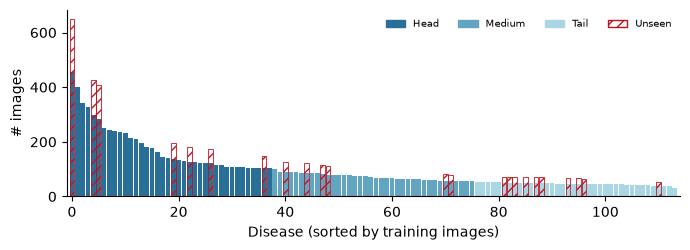

In [43]:
s = stats.sort_values('n_train', ascending=False).reset_index(drop=True)
col = s['freq_bin'].map({'head': '#2a6f97', 'medium': '#61a5c2', 'tail': '#a9d6e5'})
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.bar(s.index, s['n_train'], color=col, width=0.9)
u = s.index[s['unseen']]
ax.bar(u, s.loc[u, 'n_images'], color='none', edgecolor='#c1121f', hatch='///', width=0.9, lw=0.6)
ax.set(xlabel='Disease (sorted by training images)', ylabel='# images', xlim=(-1, len(s)))
ax.legend(handles=[Patch(color='#2a6f97', label='Head'), Patch(color='#61a5c2', label='Medium'),
                   Patch(color='#a9d6e5', label='Tail'),
                   Patch(facecolor='none', edgecolor='#c1121f', hatch='///', label='Unseen')],
          fontsize=7, frameon=False, ncol=4, loc='upper right')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG / f'data_longtail.{ext}', dpi=300, bbox_inches='tight')
plt.show()

## 7. Image cache

In [44]:
# resized RGB copies (shorter side = CACHE_SIDE) so feature extraction does not
# re-decode full-resolution files; transforms in later notebooks start from these
CACHE = OUT / 'cache'
data['cache_path'] = None
if CACHE_SIDE:
    CACHE.mkdir(exist_ok=True)
    def to_cache(row):
        dst = CACHE / f'{row[0]}.jpg'
        if not dst.exists() or FORCE:
            with Image.open(row[1]) as im:
                im = im.convert('RGB')
                s = CACHE_SIDE / min(im.size)
                if s < 1:
                    im = im.resize((round(im.width * s), round(im.height * s)), Image.BICUBIC)
                im.save(dst, quality=95)
        return str(dst)
    data['cache_path'] = pmap(to_cache, list(zip(data['md5hash'], data['path'])), 'cache')

cache: 100%|██████████| 16321/16321 [00:24<00:00, 672.54it/s]


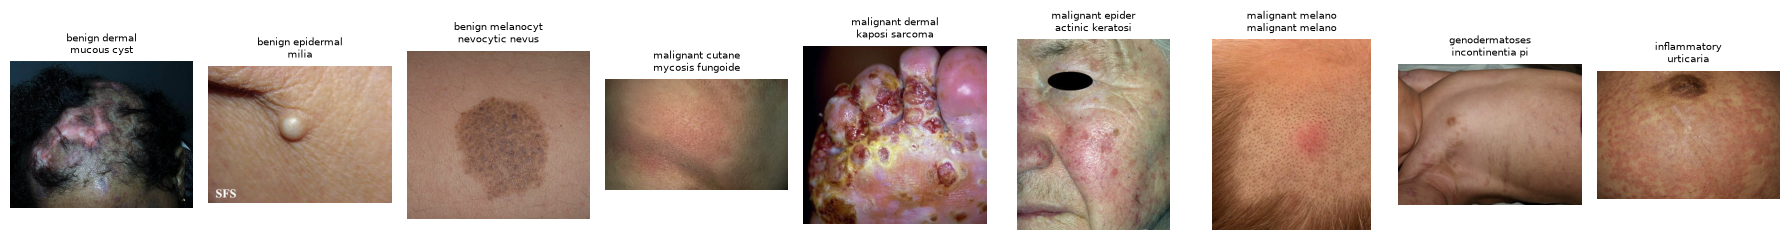

In [45]:
# sanity check: one random image per category
cats = tax['category'].unique()
fig, ax = plt.subplots(1, len(cats), figsize=(2 * len(cats), 2.4), squeeze=False)
for j, c in enumerate(cats):
    r = data[data['nine_partition_label'] == c].sample(1, random_state=SEED).iloc[0]
    ax[0, j].imshow(Image.open(r['cache_path'] or r['path']).convert('RGB'))
    ax[0, j].set_title(f"{c[:16]}\n{r['label'][:16]}", fontsize=7)
    ax[0, j].axis('off')
plt.tight_layout(); plt.show()

## 8. Save

In [46]:
cols = ['md5hash', 'disease_id', 'label', 'nine_partition_label', 'three_partition_label',
        'fitzpatrick_scale', 'skin_group', 'qc', 'w', 'h', 'path', 'cache_path',
        'dup_cluster', 'dup_size', 'split_lt', 'split_zsl', 'unseen', 'freq_bin']
data[cols].to_csv(OUT / 'meta.csv', index=False)
tax.to_csv(OUT / 'taxonomy.csv', index=False)
stats.to_csv(OUT / 'class_stats.csv', index=False)
df[df['drop_reason'].notna()][['md5hash', 'label', 'drop_reason', 'err']].to_csv(OUT / 'dropped.csv', index=False)

LOG.update(
    dropped={k: int(v) for k, v in df['drop_reason'].value_counts().items()},
    phash_thr=PHASH_THR, clean_images=len(data), diseases=len(tax),
    unseen_diseases=int(tax['unseen'].sum()),
    split_lt=data['split_lt'].value_counts().to_dict(),
    split_zsl=data['split_zsl'].value_counts().to_dict(),
    skin_group=data['skin_group'].value_counts().to_dict(), seed=SEED)
json.dump(LOG, open(OUT / 'summary.json', 'w'), indent=2, default=int)
print(json.dumps(LOG, indent=2, default=int))

{
  "csv_rows": 16577,
  "csv_dup_rows": 0,
  "image_files": 16577,
  "missing": 0,
  "files_not_in_csv": 0,
  "dup_clusters": 216,
  "drop_redundant": 201,
  "drop_conflict": 38,
  "freq_thresholds": [
    54.666666666666664,
    100.33333333333331
  ],
  "train_min": 31,
  "train_max": 455,
  "imbalance_ratio": 14.68,
  "dropped": {
    "qc_wrong_label": 17
  },
  "phash_thr": 4,
  "clean_images": 16321,
  "diseases": 114,
  "unseen_diseases": 23,
  "split_lt": {
    "train": 11432,
    "test": 3258,
    "val": 1631
  },
  "split_zsl": {
    "train": 8976,
    "test_unseen": 3503,
    "test_seen": 2561,
    "val": 1281
  },
  "skin_group": {
    "I-II": 7608,
    "III-IV": 6014,
    "V-VI": 2146,
    "unknown": 553
  },
  "seed": 42
}
